In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

import seaborn as sns


full_pumpkins = pd.read_csv('US-pumpkins.csv')

full_pumpkins.head()

,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


In [4]:

columns_to_select = ['City Name','Package','Variety', 'Origin','Item Size', 'Color']
pumpkins = full_pumpkins.loc[:, columns_to_select]

pumpkins.dropna(inplace=True)

pumpkins.info

<bound method DataFrame.info of       City Name       Package            Variety    Origin Item Size   Color
2     BALTIMORE  24 inch bins        HOWDEN TYPE  DELAWARE       med  ORANGE
3     BALTIMORE  24 inch bins        HOWDEN TYPE  VIRGINIA       med  ORANGE
4     BALTIMORE  24 inch bins        HOWDEN TYPE  MARYLAND       lge  ORANGE
5     BALTIMORE  24 inch bins        HOWDEN TYPE  MARYLAND       lge  ORANGE
6     BALTIMORE  36 inch bins        HOWDEN TYPE  MARYLAND       med  ORANGE
...         ...           ...                ...       ...       ...     ...
1694  ST. LOUIS  24 inch bins  HOWDEN WHITE TYPE  ILLINOIS      xlge   WHITE
1695  ST. LOUIS  24 inch bins  HOWDEN WHITE TYPE  ILLINOIS      xlge   WHITE
1696  ST. LOUIS  24 inch bins  HOWDEN WHITE TYPE  ILLINOIS      xlge   WHITE
1697  ST. LOUIS  24 inch bins  HOWDEN WHITE TYPE  ILLINOIS      xlge   WHITE
1698  ST. LOUIS  24 inch bins  HOWDEN WHITE TYPE  ILLINOIS      xlge   WHITE

[991 rows x 6 columns]>

Seaborn offers some neat ways to visualize your data. For example, you can compare distributions of the data for each Variety and Color in a categorical plot.

1. Create such a plot by using the catplot function, using our pumpkin data pumpkins, and specifying a color mapping for each pumpkin category (orange or white):

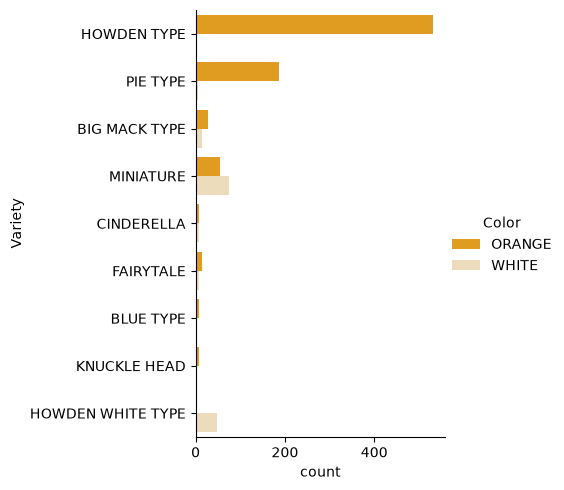

In [7]:
palette = {
'ORANGE': 'orange',
'WHITE': 'wheat',
}

sns.catplot(
data=pumpkins, y="Variety", hue="Color", kind="count",
palette=palette, 
)

1. Ordinal encoder: it suits well for ordinal variables, which are categorical variables where their data follows a logical ordering, like the Item Size column in our dataset. It creates a mapping such that each category is represented by a number, which is the order of the category in the column.

In [9]:
from sklearn.preprocessing import OrdinalEncoder

item_size_categories = [['sml', 'med', 'med-lge', 'lge', 'xlge', 'jbo', 'exjbo']]
ordinal_features = ['Item Size']
ordinal_encoder = OrdinalEncoder(categories=item_size_categories)

2. Categorical encoder: it suits well for nominal variables, which are categorical variables where their data does not follow a logical ordering, like all the features different from Item Size in our dataset. It is a one-hot encoding, which means that each category is represented by a binary column: the encoded variable is equal to 1 if the pumpkin belongs to that Variety and 0 otherwise.

In [10]:
from sklearn.preprocessing import OneHotEncoder

categorical_features = ['City Name', 'Package', 'Variety', 'Origin']
categorical_encoder = OneHotEncoder(sparse_output=False)

Then, ColumnTransformer is used to combine multiple encoders into a single step and apply them to the appropriate columns.

In [12]:
from sklearn.compose import ColumnTransformer

ct = ColumnTransformer(transformers=[
    ('ord', ordinal_encoder, ordinal_features),
    ('cat', categorical_encoder, categorical_features)
    ])

ct.set_output(transform='pandas')
encoded_features = ct.fit_transform(pumpkins)

On the other hand, to encode the label, we use the scikit-learn LabelEncoder class, which is a utility class to help normalize labels such that they contain only values between 0 and n_classes-1 (here, 0 and 1).

In [13]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
encoded_label = label_encoder.fit_transform(pumpkins['Color'])

Once we have encoded the features and the label, we can merge them into a new dataframe encoded_pumpkins.

In [14]:
encoded_pumpkins = encoded_features.assign(Color=encoded_label)

# Analyse relationships between variables
Now that we have pre-processed our data, we can analyse the relationships between the features and the label to grasp an idea of how well the model will be able to predict the label given the features. The best way to perform this kind of analysis is plotting the data. We'll be using again the Seaborn catplot function, to visualize the relationships between Item Size, Variety and Color in a categorical plot. To better plot the data we'll be using the encoded Item Size column and the unencoded Variety column.

C:\Users\amara\AppData\Local\Temp\ipykernel_12272\3754974362.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


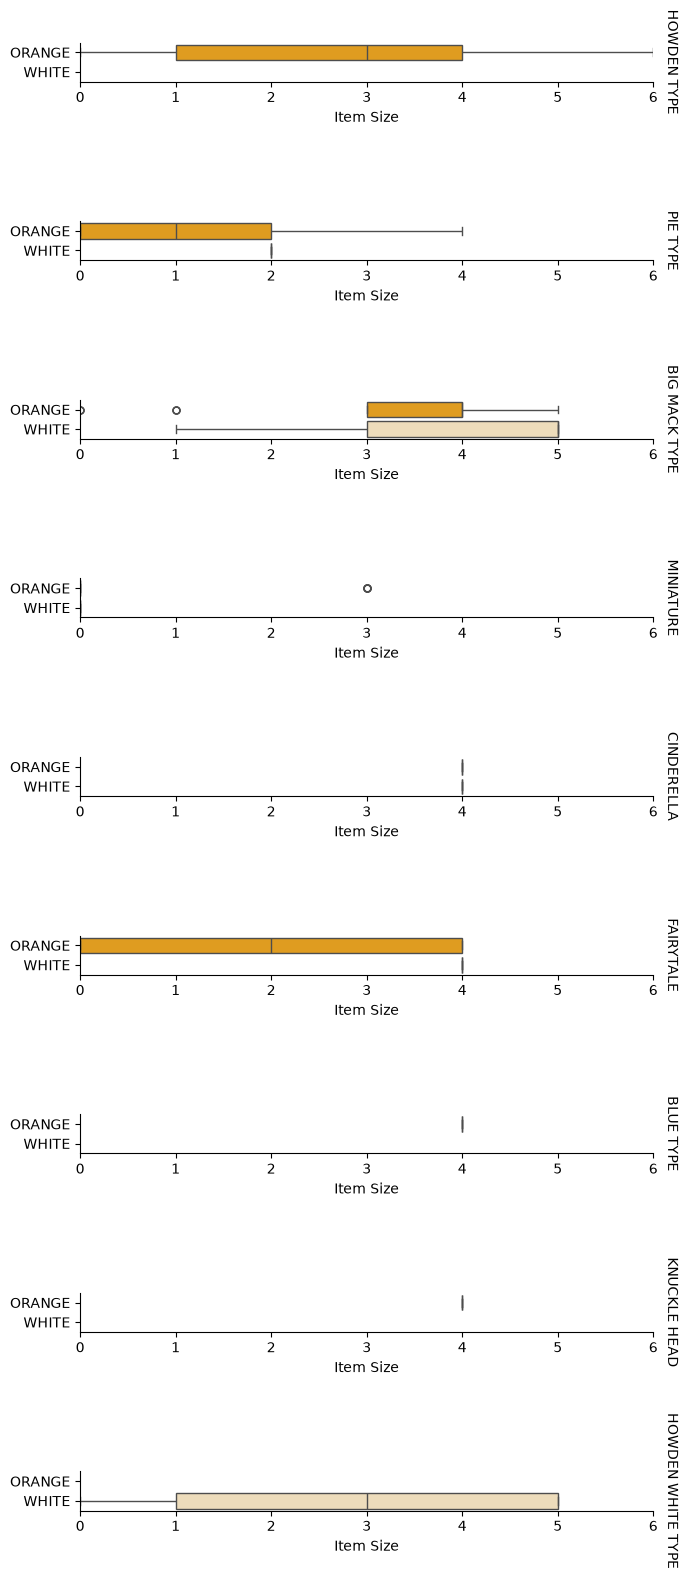

In [15]:
palette = {
'ORANGE': 'orange',
'WHITE': 'wheat',
}
pumpkins['Item Size'] = encoded_pumpkins['ord__Item Size']

g = sns.catplot(
    data=pumpkins,
    x="Item Size", y="Color", row='Variety',
    kind="box", orient="h",
    sharex=False, margin_titles=True,
    height=1.8, aspect=4, palette=palette,
)
g.set(xlabel="Item Size", ylabel="").set(xlim=(0,6))
g.set_titles(row_template="{row_name}")

# Use a swarm plot
Since Color is a binary category (White or Not), it needs 'a specialized approach to visualization'. There are other ways to visualize the relationship of this category with other variables.

You can visualize variables side-by-side with Seaborn plots.

 1. Try a 'swarm' plot to show the distribution of values:

C:\Users\amara\AppData\Local\Temp\ipykernel_12272\133969970.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x="Color", y="ord__Item Size", data=encoded_pumpkins, palette=palette)
C:\Users\amara\Documents\Notebooks\ml-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 63.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\amara\Documents\Notebooks\ml-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 21.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='Color', ylabel='ord__Item Size'>

C:\Users\amara\Documents\Notebooks\ml-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 79.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\amara\Documents\Notebooks\ml-env\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 35.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


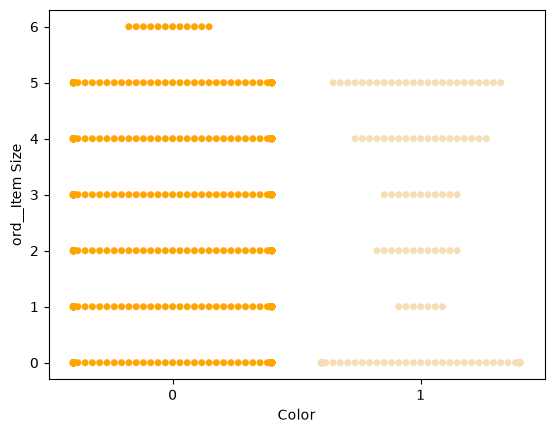

In [20]:
palette = {
    '0': 'orange',
    '1': 'wheat'
}
sns.swarmplot(x="Color", y="ord__Item Size", data=encoded_pumpkins, palette=palette)

# Build A Model

1. Select the variables you want to use in your classification model and split the training and test sets calling train_test_split():

In [21]:
from sklearn.model_selection import train_test_split

X = encoded_pumpkins[encoded_pumpkins.columns.difference(['Color'])]
y = encoded_pumpkins['Color']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


Now you can train your model, by calling fit() with your training data, and print out its result:

In [22]:
from sklearn.metrics import f1_score, classification_report 
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions))
print('Predicted labels: ', predictions)
print('F1-score: ', f1_score(y_test, predictions))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       166
           1       0.85      0.67      0.75        33

    accuracy                           0.92       199
   macro avg       0.89      0.82      0.85       199
weighted avg       0.92      0.92      0.92       199

Predicted labels:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0
 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 1 1]
F1-score:  0.7457627118644068


# Better comprehension via a confusion matrix
While you can get a scoreboard report terms by printing out the items above, you might be able to understand your model more easily by using a confusion matrix to help us understand how the model is performing.

- A 'confusion matrix' (or 'error matrix') is a table that expresses your model's true vs. false positives and negatives, thus gauging the accuracy of predictions.

To use a confusion metrics, call confusion_matrix():

In [23]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, predictions)

array([[162,   4],
       [ 11,  22]])

In Scikit-learn, confusion matrices Rows (axis 0) are actual labels and columns (axis 1) are predicted labels.

|                  | Predicted Negative | Predicted Positive |
|------------------|-------------------|-------------------|
| Actual Negative  | TN                | FP                |
| Actual Positive  | FN                | TP                |

What's going on here? Let's say our model is asked to classify pumpkins between two binary categories, category 'white' and category 'not-white'.

- If your model predicts a pumpkin as not white and it belongs to category 'not-white' in reality we call it a true negative, shown by the top left number.
- If your model predicts a pumpkin as white and it belongs to category 'not-white' in reality we call it a false negative, shown by the bottom left number.
- If your model predicts a pumpkin as not white and it belongs to category 'white' in reality we call it a false positive, shown by the top right number.
- If your model predicts a pumpkin as white and it belongs to category 'white' in reality we call it a true positive, shown by the bottom right number.
  
As you might have guessed it's preferable to have a larger number of true positives and true negatives and a lower number of false positives and false negatives, which implies that the model performs better.

How does the confusion matrix relate to precision and recall? Remember, the classification report printed above showed precision (0.85) and recall (0.67).

Precision = tp / (tp + fp) = 22 / (22 + 4) = 0.8461538461538461

Recall = tp / (tp + fn) = 22 / (22 + 11) = 0.6666666666666666

✅ Q: According to the confusion matrix, how did the model do? A: Not bad; there are a good number of true negatives but also a few false negatives.

Let's revisit the terms we saw earlier with the help of the confusion matrix's mapping of TP/TN and FP/FN:

🎓 Precision: TP/(TP + FP) The fraction of relevant instances among the retrieved instances (e.g. which labels were well-labeled)

🎓 Recall: TP/(TP + FN) The fraction of relevant instances that were retrieved, whether well-labeled or not

🎓 f1-score: (2 * precision * recall)/(precision + recall) A weighted average of the precision and recall, with best being 1 and worst being 0

🎓 Support: The number of occurrences of each label retrieved

🎓 Accuracy: (TP + TN)/(TP + TN + FP + FN) The percentage of labels predicted accurately for a sample.

🎓 Macro Avg: The calculation of the unweighted mean metrics for each label, not taking label imbalance into account.

🎓 Weighted Avg: The calculation of the mean metrics for each label, taking label imbalance into account by weighting them by their support (the number of true instances for each label).

Let's do one more visualization to see the so-called 'ROC' curve:

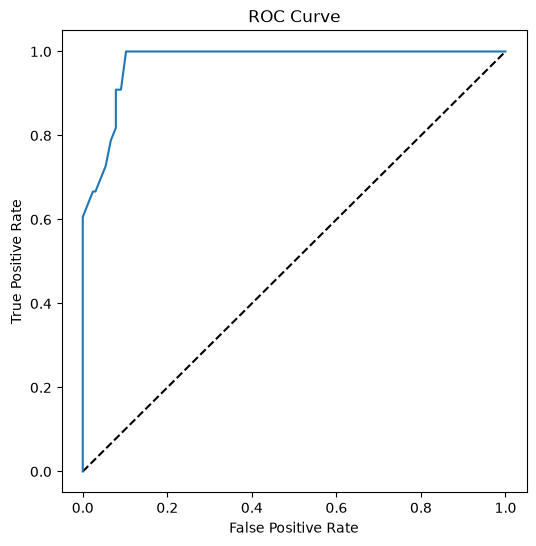

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

y_scores = model.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])

fig = plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

Using Matplotlib, plot the model's Receiving Operating Characteristic or ROC. ROC curves are often used to get a view of the output of a classifier in terms of its true vs. false positives. "ROC curves typically feature true positive rate on the Y axis, and false positive rate on the X axis." Thus, the steepness of the curve and the space between the midpoint line and the curve matter: you want a curve that quickly heads up and over the line. In our case, there are false positives to start with, and then the line heads up and over properly:

Finally, use Scikit-learn's roc_auc_score API to compute the actual 'Area Under the Curve' (AUC):

In [25]:
auc = roc_auc_score(y_test,y_scores[:,1])
print(auc)

0.9749908725812341


The result is 0.9749908725812341. Given that the AUC ranges from 0 to 1, you want a big score, since a model that is 100% correct in its predictions will have an AUC of 1; in this case, the model is pretty good.